# 4. VISUALIZACIONES sistemas

Para realizar las visualizaciones correspondientes para checkear nuestra hipotesis:
Se necesitan hacer diferentes variables intermedias y agrupaciones algo complicadas.
Ademas tengo que hacer y llamar una funcion en los diferentes calculos de diferentes visualizaciones, para rellenar los graficos numericamente

In [4]:
def etiquetas(ax, total):
    for barras in ax.containers:
        ax.bar_label(barras,fmt=lambda n: f"{n:.0f} ({n / total:.1%})",padding=3)

Carga de archivos

In [9]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve()

if ROOT.name == "jupyter":
    ROOT = ROOT.parent

if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
CLEAN = ROOT / "CLEAN"

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from src.calculos_visualizaciones.funciones import etiquetas

df = pd.read_csv( CLEAN /"dataset_merged.csv")

 ### Resumen general del dataset

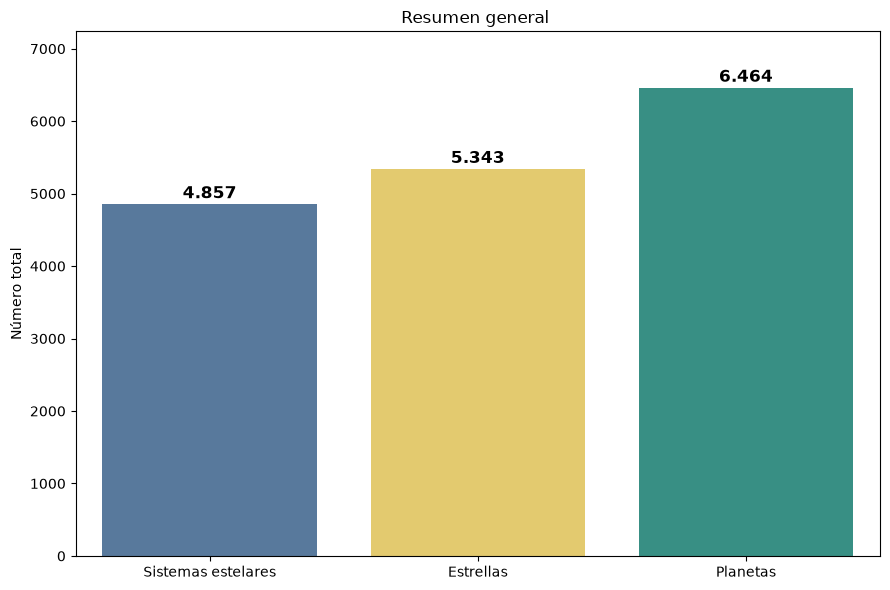

In [10]:
planetas = df.drop_duplicates(subset=["hostname", "pl_name"]).copy()
sistemas = planetas.drop_duplicates(subset="hostname").copy()
numero_sistemas = sistemas["hostname"].nunique()
numero_estrellas = int(pd.to_numeric(sistemas["sy_snum"],errors="coerce").sum())
numero_planetas = len(planetas)

resumen_general = pd.Series({"Sistemas estelares": numero_sistemas,"Estrellas": numero_estrellas,
    "Planetas": numero_planetas})

colores = ["#4C78A8", "#F6D55C", "#2A9D8F"]

plt.figure(figsize=(9, 6))

ax = sns.barplot(x=resumen_general.index,y=resumen_general.values,hue=resumen_general.index,palette=colores,legend=False)

for posicion, valor in enumerate(resumen_general.values):
    plt.text(posicion,valor + 80,f"{valor:,}".replace(",", "."),ha="center",fontsize=12,fontweight="bold")

plt.ylim(0, resumen_general.max() * 1.12)
plt.title("Resumen general ")
plt.xlabel("")
plt.ylabel("Número total")
plt.tight_layout()

plt.savefig(ROOT / "imagenes" / "Resumen general del dataset.png",dpi=300,bbox_inches="tight")
plt.show()

### 0.Número de estrellas por sistema

0.Número de estrellas por sistema

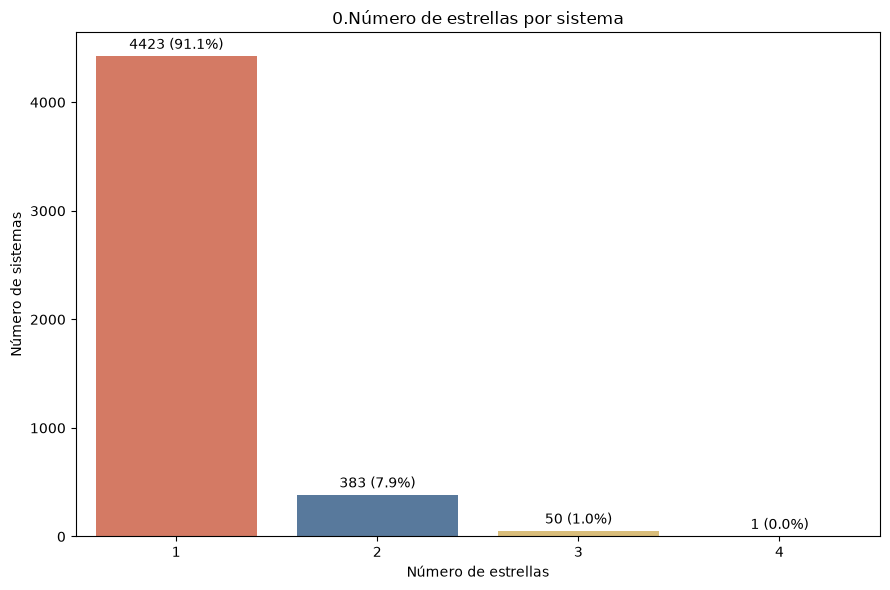

In [11]:
conteo_estrellas_sistema = (
    pd.to_numeric(sistemas["sy_snum"], errors="coerce").dropna().astype(int).value_counts().sort_index())

plt.figure(figsize=(9, 6))
colores=["#E76F51", "#4C78A8", "#E9C46A", "#E76F51"]
sns.barplot(x=conteo_estrellas_sistema.index,y=conteo_estrellas_sistema.values,hue=conteo_estrellas_sistema.index,
    palette=colores,legend=False)

plt.title("0.Número de estrellas por sistema")
plt.xlabel("Número de estrellas")
plt.ylabel("Número de sistemas")

etiquetas(plt.gca(),conteo_estrellas_sistema.sum())

plt.tight_layout()

plt.savefig(ROOT / "imagenes" / "0.Numero de estrellas por sistema.png",dpi=300,bbox_inches="tight")

plt.show()

### 1. Numero de estrellas por sistema 

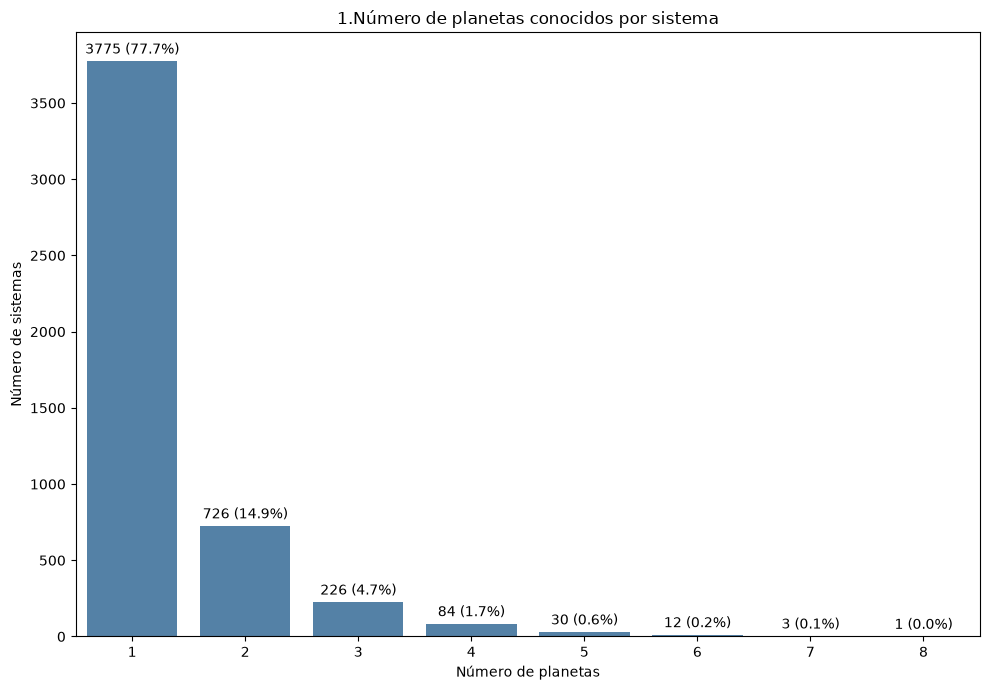

In [12]:
planetas = df.drop_duplicates(subset=["hostname", "pl_name"]).copy()
sistemas = planetas.drop_duplicates(subset="hostname").copy()
orden = sorted(sistemas["sy_pnum"].unique())

plt.figure(figsize=(10, 7))
sns.countplot(data=sistemas,x="sy_pnum",order=orden,color="steelblue")

plt.title("1.Número de planetas conocidos por sistema")
plt.xlabel("Número de planetas")
plt.ylabel("Número de sistemas")
plt.tight_layout()
etiquetas(plt.gca(), sistemas["sy_pnum"].notna().sum())
plt.savefig(ROOT / "imagenes" /"1.planetas por sistema.png",dpi=300,bbox_inches="tight")
plt.show()

### 2. Sistemas con planetas pequenos en la zona interior 3. Ley de Kepler

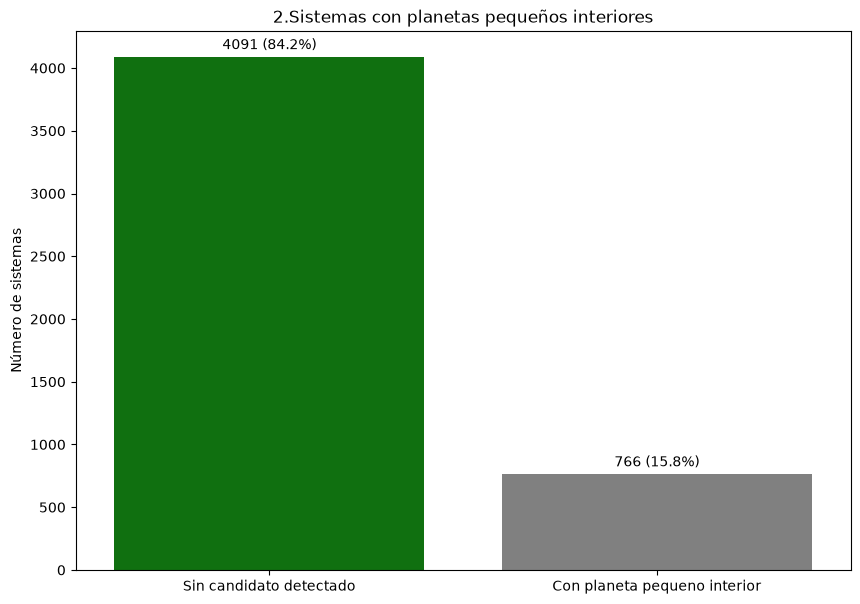

In [8]:
# 2. Sistemas con planetas pequenos en la zona interior 3. Ley de Kepler

validos_orbita = ((df["st_mass_y"] > 0) & (df["st_mass_y"] < 100) &(df["pl_orbper_y"] > 0))
df["a_ua"] = float("nan")
df.loc[validos_orbita, "a_ua"] = (df.loc[validos_orbita, "st_mass_y"]
* (df.loc[validos_orbita, "pl_orbper_y"] / 365.25) ** 2) ** (1 / 3)

df["pequeno_interior"] = ((df["pl_rade_y"] >= 0.5) &(df["pl_rade_y"] <= 1.6) &(df["a_ua"] < 1.5))

pla_peq_int = (df.groupby("hostname")["pequeno_interior"].any()
    .map({True: "Con planeta pequeno interior", False: "Sin candidato detectado"})
    .value_counts())

plt.figure(figsize=(10, 7))
sns.barplot( x=pla_peq_int.index ,y=pla_peq_int.values ,hue=pla_peq_int.index,palette=["green","gray"])

plt.title("2.Sistemas con planetas pequeños interiores")
plt.xlabel("")
plt.ylabel("Número de sistemas")
etiquetas(plt.gca(), pla_peq_int.sum())
plt.savefig(ROOT / "imagenes" /"2. Sistemas con planetas pequenos en la zona interior.png",dpi=300,bbox_inches="tight")
plt.show()

### 3. Sistemas con y sin gigantes calientes


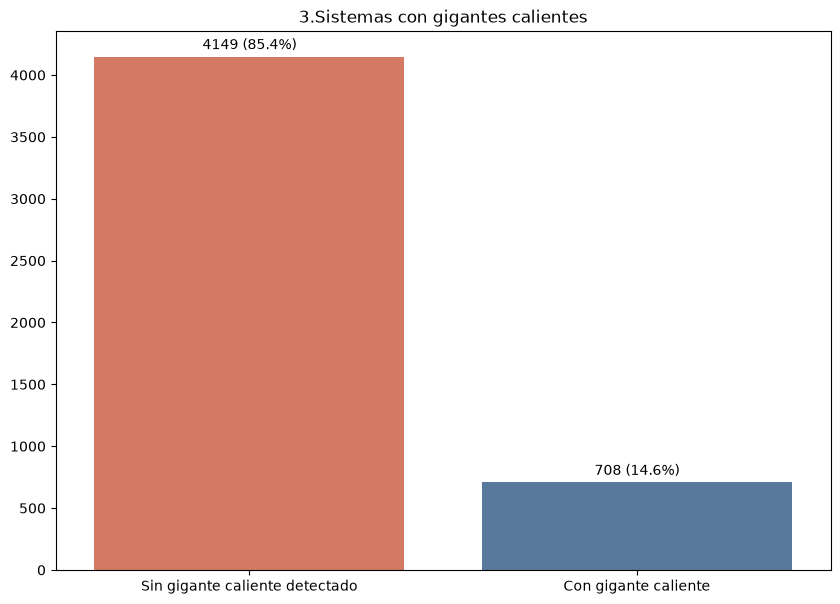

In [ ]:
df["gigante_caliente"] = ((df["pl_rade_y"] >= 8) &(df["pl_orbper_y"] < 10))

gigantes_por_sistema = df.groupby("hostname").agg(
    gigante_caliente=("gigante_caliente", "any"))

sistemas_gigantes_calientes = (gigantes_por_sistema["gigante_caliente"].value_counts()
    .rename(index={True: "Con gigante caliente",False: "Sin gigante caliente detectado"}))

colores=["#E76F51", "#4C78A8"]

plt.figure(figsize=(10, 7))
sns.barplot( x=sistemas_gigantes_calientes.index ,y=sistemas_gigantes_calientes.values ,
            hue=sistemas_gigantes_calientes.index,palette=colores)

plt.title("3.Sistemas con gigantes calientes")
plt.xlabel("")
plt.ylabel("")
etiquetas(plt.gca(), sistemas_gigantes_calientes.sum())
plt.savefig(ROOT / "imagenes" /"3. Sistemas con gigantes calientes.png",dpi=300,bbox_inches="tight")
plt.show()

### 4. Sistemas con gigantes exteriores tipo Jupiter/Saturno

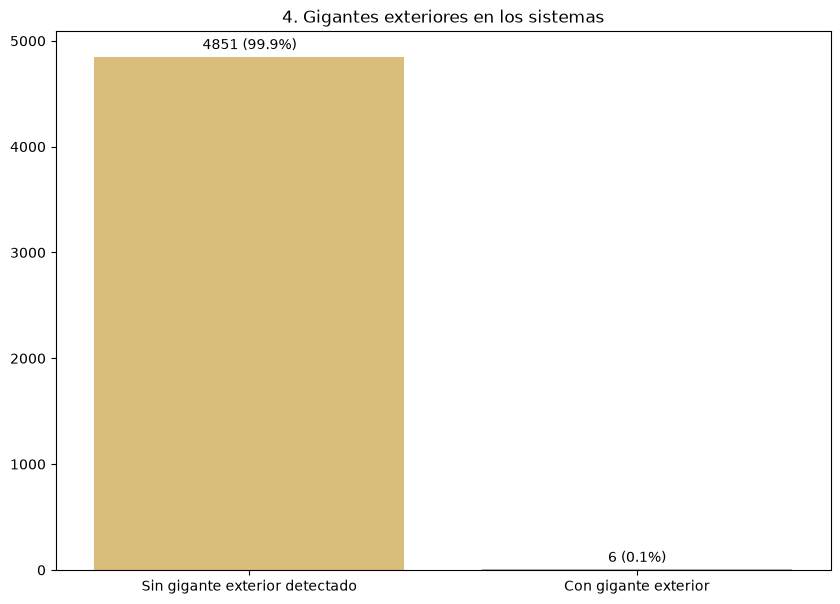

In [ ]:
df["gigante_exterior"] = ((df["pl_rade_y"] >= 8) &(df["a_ua"] >= 3))

sistemas_gigantes_exteriores = (df.groupby("hostname")["gigante_exterior"].any()
    .map({True: "Con gigante exterior", False: "Sin gigante exterior detectado"}).value_counts())

colores=["#E9C46A", "#B0B0B0"]

plt.figure(figsize=(10, 7))
sns.barplot( x=sistemas_gigantes_exteriores.index ,y=sistemas_gigantes_exteriores.values ,
            hue=sistemas_gigantes_exteriores.index,palette=colores)

plt.title("4. Gigantes exteriores en los sistemas")
plt.xlabel("")
plt.ylabel("")
etiquetas(plt.gca(), sistemas_gigantes_exteriores.sum())
plt.savefig(ROOT / "imagenes" /"4. Sistemas con gigantes exteriores.png",dpi=300,bbox_inches="tight")
plt.show()

### 5. Sistemas con al menos un planeta en zona habitable estimada

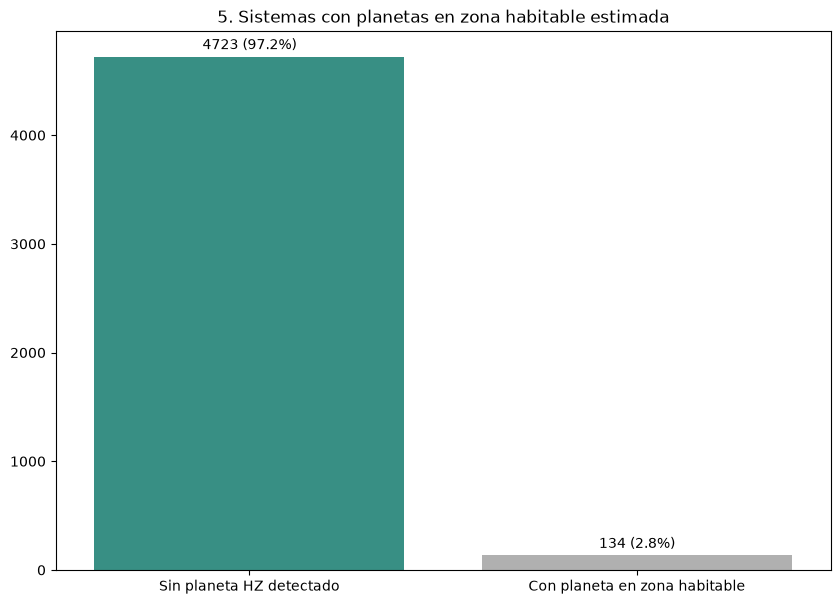

In [ ]:


temperatura_sol = 5772

validos_estrella = ((df["st_teff_y"] > 0) & (df["st_rad"] > 0))

df["luminosidad_relativa"] = float("nan")
df.loc[validos_estrella, "luminosidad_relativa"] = (df.loc[validos_estrella, "st_rad"] ** 2
* (df.loc[validos_estrella, "st_teff_y"] / temperatura_sol) ** 4)

df["zh_interior"] = 0.95 * df["luminosidad_relativa"] ** 0.5
df["zh_exterior"] = 1.67 * df["luminosidad_relativa"] ** 0.5

df["en_zh"] = ((df["a_ua"] >= df["zh_interior"]) &(df["a_ua"] <= df["zh_exterior"]))

sistemas_zh = (
    df.groupby("hostname")["en_zh"].any()
    .map({True: "Con planeta en zona habitable", False: "Sin planeta HZ detectado"}).value_counts())

colores=["#2A9D8F", "#B0B0B0"]

plt.figure(figsize=(10, 7))
sns.barplot( x=sistemas_zh .index ,y=sistemas_zh .values ,
            hue=sistemas_zh .index,palette=colores)

plt.title("5. Sistemas con planetas en zona habitable estimada")
plt.xlabel("")
plt.ylabel("")
etiquetas(plt.gca(), sistemas_zh.sum())
plt.savefig(ROOT / "imagenes" /"5. Sistemas con al menos un planeta en zona habitable estimada.png",dpi=300,bbox_inches="tight")
plt.show()